## **Modelos de Machine Learning AutoML**



### **Bibliotecas**

In [1]:
import pandas as pd                                                                # Manipulação de dados
import numpy as np                                                                 # Realização de cálculos específicos
import matplotlib.pyplot as plt                                                    # Visualização de dados 
from scipy.stats import randint, uniform, loguniform                               # Geração de valores aleatórios
from sklearn.compose import ColumnTransformer                                      # Transformação de colunas
from sklearn.preprocessing import StandardScaler, OneHotEncoder                    # Transformação de colunas
from sklearn.model_selection import train_test_split                               # Validação simples
from sklearn.utils.class_weight import compute_sample_weight                       # Cálculo de pesos para observações
from sklearn.calibration import CalibratedClassifierCV                             # Calibração de probabilidades
from sklearn.calibration import calibration_curve                                  # Gráfico de curva de calibração
from sklearn.metrics import brier_score_loss                                       # Score de Brier
from sklearn.preprocessing import label_binarize                                   # Binarização da resposta (Score de Brier one-vs-rest)
from sklearn.metrics import accuracy_score, balanced_accuracy_score                # Análise de desempenho: acurácia e acurácia balanceada
from sklearn.metrics import auc, roc_auc_score, roc_curve              # Análise de desempenho: KS e AUC
from sklearn.inspection import permutation_importance                              # Importância de variáveis por permutação
import shap                                                                        # Interpretabilidade de variáveis nos modelos
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV

In [2]:
dados = pd.read_csv('../data/00_final_dataset.csv')

### **Etapa 1: Especificação de variáveis e análise bivariada**

*Lista de nomes das variáveis explicativas, separando em quantitativas e qualitativas*

In [3]:
# Variáveis explicativas quantitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quanti = [
  # --- Informações Físicas e do Draft ---
    'draft_year', 
    'draft_age', 
    'years_college', 
    'mock_pick',        # Expectativa do mercado antes do draft
    'height_cm', 
    'weight_kg',

    # --- Estatísticas Avançadas (Eficiência) ---
    'true_shooting_pct', 
    'effective_field_goal_pct', 
    'usage_pct',
    'offensive_win_shares', 
    'defensive_win_shares', 
    'win_shares_per_40min',
    'three_point_attempt_rate', 
    'free_throw_attempt_rate',

    # --- Estatísticas de Arremesso (Volume e Precisão) ---
    'field_goal_attempted', 
    'three_pointers_made', 
    'three_pointers_attempted', 
    'three_point_pct',
    'free_throw_attempted', 
    'free_throw_pct',

    # --- Estatísticas Tradicionais (Médias por Jogo) ---
    'points', 
    'assists', 
    'total_rebounds', 
    'offensive_rebounds', 
    'defensive_rebounds',
    'steals', 
    'blocks', 
    'turnovers', 
    'personal_fouls',

    # --- Experiência no College (Acumulados) ---
    'career_games', 
    'career_starts', 
    'career_minutes', 
    'career_awards_count'
]

# Variáveis explicativas qualitativas (deixar vazio [] caso não haja nenhuma)
lista_X_quali = [
    'college_name', 
    'conference', 
    'position'
]

*Objetos para variável resposta (y) e explicativas (X)*

In [4]:
y = dados['target_label']
X = dados[lista_X_quali + lista_X_quanti]

In [5]:
# Ordenando as categorias da resposta y
ordem_categorias = ['Bust', 'Rotation', 'Starter', 'Star']
y = y.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True))

### **Etapa 2: Divisão de treino e teste externo**

*Divisão inicial*

In [6]:
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y,
                                                        test_size=0.2,
                                                        stratify=y,
                                                        random_state=123)

*Representação das categorias de y como números (requerido por alguns algoritmos e para calibração)*

In [7]:
y_treino = y_treino.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)
y_teste = y_teste.astype(pd.CategoricalDtype(categories=ordem_categorias, ordered=True)).cat.codes.rename(y.name)

In [8]:
y_treino.value_counts()

target_label
0    397
1    221
2    103
3     42
Name: count, dtype: int64

### **Etapa 3: Pré-processamento de variáveis explicativas**

*Definição das funções de pré-processamento: Padronização das variáveis quantitativas + Codificação one-hot para variáveis qualitativas*

In [9]:
preprocessador = ColumnTransformer(transformers=[
    ("quanti", StandardScaler(), lista_X_quanti),
    ("quali", OneHotEncoder(sparse_output=False, drop="first", handle_unknown='ignore'), lista_X_quali)
],
    remainder="passthrough"
)

*Criação do pré-processamento no conjunto de treino* <br>

In [10]:
X_treino_tratada = preprocessador.fit_transform(X_treino)  # O pré-processamento não deve envolver o conjunto de teste externo, que deve ficar reservado apenas para aplicações de resultados já obtidos, e nunca construções
if lista_X_quali:
    nomes_quali = list(preprocessador.named_transformers_['quali'].get_feature_names_out(lista_X_quali))
else:
    nomes_quali = []
nomes_variaveis = list(lista_X_quanti) + nomes_quali

In [11]:
X_treino_tratada = pd.DataFrame(X_treino_tratada, columns=nomes_variaveis)
X_treino_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,conference_Big Ten,conference_CUSA,conference_MWC,conference_Pac-10,conference_Pac-12,conference_SEC,conference_Small_Conference,conference_WCC,position_Forward,position_Guard
0,0.929730,0.318081,1.031384,0.042123,-0.062836,-1.005609,1.264503,1.024746,0.317420,-0.584000,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-1.393942,1.023593,1.031384,0.456826,-1.135495,0.067339,1.415145,0.762118,-0.686887,1.232272,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,0.431800,1.729105,1.031384,1.545421,1.395497,1.838138,0.532816,1.024746,-0.082525,0.702526,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.095707,-1.798454,-1.594687,-0.579932,0.925456,0.686682,-0.134311,0.461972,-0.349156,-1.113746,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,-1.061989,0.318081,1.031384,1.545421,-0.605192,-0.961993,0.317614,0.161825,-1.424564,-0.129932,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


*Aplicação do pré-processamento no conjunto de teste externo*

In [12]:
X_teste_tratada = preprocessador.transform(X_teste)  # Note que o mesmo objeto de pré-processamento deve ser utilizado, agora com 'transform' em vez de 'fit_transform'
X_teste_tratada = pd.DataFrame(X_teste_tratada, columns=nomes_variaveis)
X_teste_tratada.head()

,draft_year,draft_age,years_college,mock_pick,height_cm,weight_kg,true_shooting_pct,effective_field_goal_pct,usage_pct,offensive_win_shares,...,conference_Big Ten,conference_CUSA,conference_MWC,conference_Pac-10,conference_Pac-12,conference_SEC,conference_Small_Conference,conference_WCC,position_Forward,position_Guard
0,-0.398083,0.318081,1.031384,0.197636,0.009478,-0.604344,-0.349513,-0.719854,-1.771183,-0.432644,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0.265824,-1.798454,-1.594687,-1.461176,-0.062836,0.651790,-0.155831,-0.569781,-0.793539,0.324136,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-0.564059,0.318081,1.031384,0.923367,-0.677506,-0.682852,-0.521675,-0.363431,-0.326936,-0.659678,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,1.427660,1.023593,1.031384,0.353150,-0.376197,-0.464774,0.554336,0.293139,-1.482334,0.172780,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,-1.227966,0.318081,1.031384,1.545421,0.093844,-0.211802,2.082272,1.718834,-0.082525,1.686340,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


### **Etapa 4: Escolha do modelo**

In [ ]:
pesos_treino = compute_sample_weight(class_weight='balanced', y=y_treino)  


# 1. Definindo os modelos pesados que vamos testar
modelos = {
    'LogisticRegression': LogisticRegression(multi_class='multinomial', solver='lbfgs', class_weight='balanced', random_state=123),
    'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=123),
    'XGBoost': XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', random_state=123),
    'LightGBM': LGBMClassifier(objective='multiclass', class_weight='balanced', random_state=123, verbose=-1)
}

# 2. Definindo as "chaves" (hiperparâmetros) que o algoritmo vai tentar abrir
parametros = {
    'LogisticRegression': {
        'C': [0.01, 0.1, 1.0, 10.0],
        'max_iter': [1000, 2000]
    },
    'RandomForest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 15],
        'min_samples_split': [2, 5, 10]
    },
    'XGBoost': {
        'n_estimators': [100, 200, 300],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.01, 0.05, 0.1],
        'subsample': [0.8, 1.0]
    },
    'LightGBM': {
        'n_estimators': [100, 200, 300],
        'max_depth': [-1, 5, 10],
        'learning_rate': [0.01, 0.05, 0.1],
        'num_leaves': [31, 50, 100]
    }
}

# 3. Rodando o "AutoML" (Busca do melhor modelo focando no AUC-OVR)
melhor_auc = 0
modelo_final = None  # Esta variável vai guardar o campeão!
nome_melhor_modelo = ""

print("Iniciando a Batalha de Algoritmos...\n")

for nome, algoritmo in modelos.items():
    print(f"Treinando e otimizando: {nome}...")
    
    busca = RandomizedSearchCV(
        estimator=algoritmo,
        param_distributions=parametros[nome],
        n_iter=100,                # Sorteia 10 combinações diferentes
        scoring='roc_auc_ovr',    # Foco total em separar as 4 classes (Bust a Star)
        cv=3,                     # Validação cruzada com 3 dobras
        random_state=123,
        n_jobs=-1                 # Usa todos os núcleos do seu processador para ir mais rápido
    )
    
    # O XGBoost exige os pesos das classes no .fit(), a Random Forest já faz isso nativamente
    if nome == "XGBoost":
        busca.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)
    else:
        busca.fit(X_treino_tratada, y_treino)
        
    print(f"Melhor AUC-OVR (Validação Cruzada) para {nome}: {busca.best_score_:.3f}\n")
    
    # Verifica se este modelo bateu o recorde
    if busca.best_score_ > melhor_auc:
        melhor_auc = busca.best_score_
        modelo_final = busca.best_estimator_
        nome_melhor_modelo = nome

print(f"🏆 O GRANDE VENCEDOR FOI: {nome_melhor_modelo} (com AUC = {melhor_auc:.3f})")

# Opcional: Mostrar os hiperparâmetros que a máquina escolheu
print(f"Hiperparâmetros otimizados: {modelo_final.get_params()}")

Iniciando a Batalha de Algoritmos...

Treinando e otimizando: LogisticRegression...


c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 8 is smaller than n_iter=100. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 27 is smaller than n_iter=100. Running 27 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Melhor AUC-OVR (Validação Cruzada) para LogisticRegression: 0.712

Treinando e otimizando: RandomForest...
Melhor AUC-OVR (Validação Cruzada) para RandomForest: 0.695

Treinando e otimizando: XGBoost...


c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 54 is smaller than n_iter=100. Running 54 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Melhor AUC-OVR (Validação Cruzada) para XGBoost: 0.685

Treinando e otimizando: LightGBM...


c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\model_selection\_search.py:317: UserWarning: The total space of parameters 81 is smaller than n_iter=100. Running 81 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


Melhor AUC-OVR (Validação Cruzada) para LightGBM: 0.677

🏆 O GRANDE VENCEDOR FOI: LogisticRegression (com AUC = 0.712)
Hiperparâmetros otimizados: {'C': 0.1, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'multinomial', 'n_jobs': None, 'penalty': 'l2', 'random_state': 123, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


*Retreino do modelo no conjunto de treino completo*

In [14]:
# 1. Configurar o modelo com os melhores hiperparâmetros encontrados
modelo = modelo_final.get_params()

# 2. Lógica de Ponderação (Para evitar aplicar peso duas vezes)
# Se for XGBoost, ele PRECISA dos pesos manuais no .fit()
if "XGB" in type(modelo).__name__:
    print(f"Detectado XGBoost: Calculando e aplicando sample_weights manuais...")
    pesos_treino = compute_sample_weight(class_weight='balanced', y=y_treino)
    modelo.fit(X_treino_tratada, y_treino, sample_weight=pesos_treino)

# Se for Random Forest ou LightGBM, eles já têm class_weight='balanced' embutido
else:
    print(f"Detectado {type(modelo).__name__}: Usando class_weight interno (sem sample_weight)...")
    # Verificação de segurança: Garantir que o parâmetro interno está ligado
    if hasattr(modelo, 'class_weight') and modelo.class_weight is None:
        modelo.set_params(class_weight='balanced')
        
    modelo_final.fit(X_treino_tratada, y_treino)

print("Modelo Final treinado com sucesso!")

Detectado dict: Usando class_weight interno (sem sample_weight)...
Modelo Final treinado com sucesso!


c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


### **Etapa 5: Calibração e análises adicionais no conjunto de teste externo**

*Aplicação do modelo final no conjunto de teste externo*

In [15]:
p_hat_teste = modelo_final.predict_proba(X_teste_tratada)
classes = modelo_final.classes_

*Atribuição da categoria de resposta predita pelo modelo, com base na maior probabilidade*

In [16]:
y_hat_teste = classes[p_hat_teste.argmax(axis=1)]

*Verificação gráfica de calibração das probabilidades*

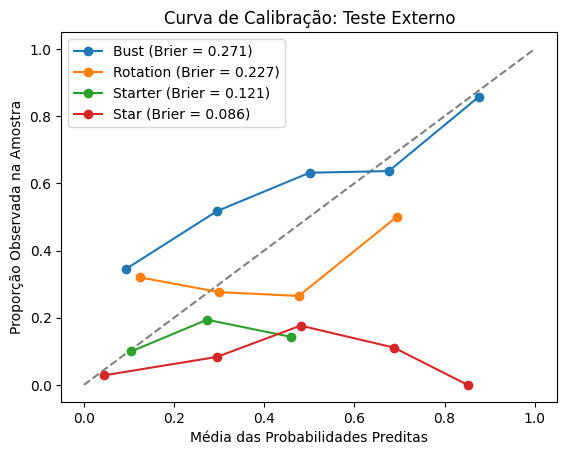

In [17]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

***(Se necessário)*** *Atualização de probabilidades preditas no teste, por meio de recalibração das probabilidades no conjunto de treino*

In [18]:
# Recalibração do modelo no treino - escolha o método: 'isotonic' (n > 1000) ou 'sigmoid'
modelo_final_calibrado = CalibratedClassifierCV(modelo_final, method='sigmoid', cv=5)
modelo_final_calibrado.fit(X_treino_tratada, y_treino)

# Armazenamento de probabilidades não calibradas e cálculo das probabilidades calibradas
p_hat_teste_nao_calibradas = p_hat_teste
p_hat_teste = modelo_final_calibrado.predict_proba(X_teste_tratada)

c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Pytho

***(Em caso de subamostragem)*** *Correção de probabilidades preditas no teste, por conta de subamostragem*

In [19]:
# Cálculo de razões entre as proporções originais (antes da subamostragem) e das proporções novas (após subamostragem)
dist_y_pre_reamostragem = pd.Series(y_treino).value_counts(normalize=True).reindex(classes).to_numpy()
dist_y_pos_reamostragem = pd.Series(y_treino).value_counts(normalize=True).reindex(classes).to_numpy()
w = dist_y_pre_reamostragem / dist_y_pos_reamostragem

# Armazenamento de probabilidades calibradas e cálculo das probabilidades calibradas + corrigidas após subamostragem
p_hat_teste_calibradas = p_hat_teste
p_hat_teste = p_hat_teste * w
p_hat_teste = p_hat_teste / p_hat_teste.sum(axis=1, keepdims=True)

***(Se necessário)*** *Verificação gráfica de calibração das probabilidades - atualização pós calibração*

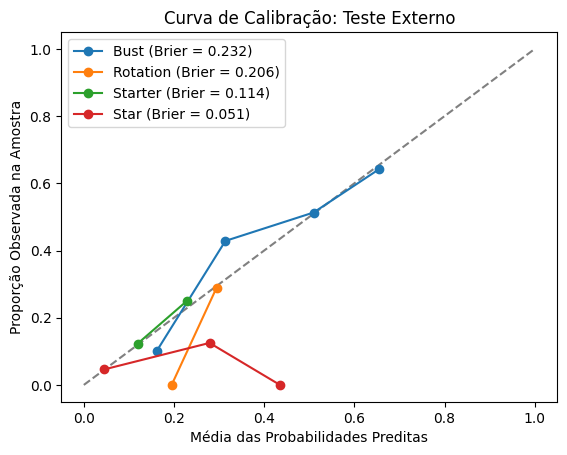

In [20]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [21]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste)
tabela.index = np.asarray(ordem_categorias)[tabela.index]
tabela.columns = np.asarray(ordem_categorias)[tabela.columns]
tabela

,Bust,Rotation,Starter,Star
Bust,57,23,7,13
Rotation,24,11,8,12
Starter,6,9,4,7
Star,1,2,4,3


In [22]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

,Bust,Rotation,Starter,Star
Bust,0.570,0.230,0.070,0.130
Rotation,0.436,0.200,0.145,0.218
Starter,0.231,0.346,0.154,0.269
Star,0.100,0.200,0.400,0.300


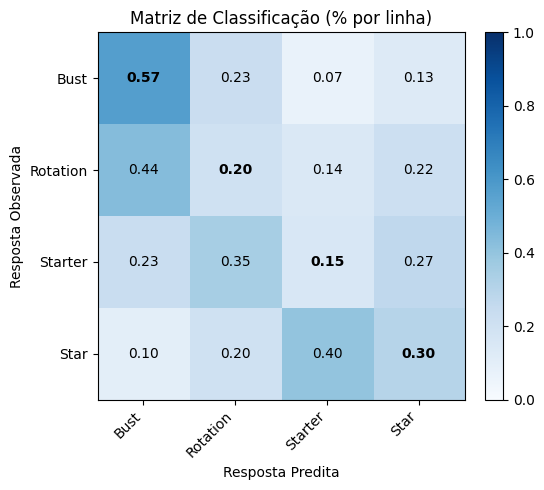

In [23]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [24]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

,Bust,Rotation,Starter,Star
Bust,0.648,0.511,0.304,0.371
Rotation,0.273,0.244,0.348,0.343
Starter,0.068,0.200,0.174,0.200
Star,0.011,0.044,0.174,0.086


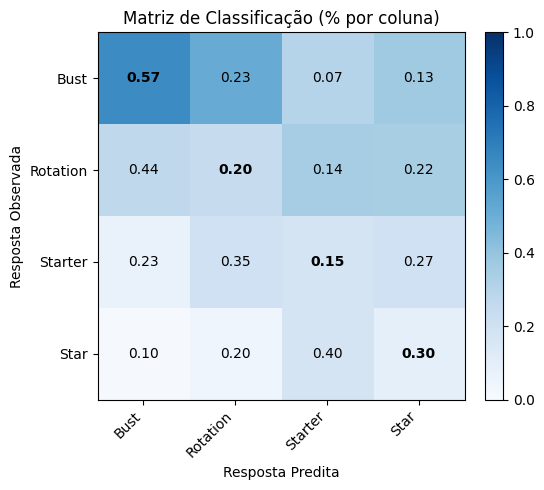

In [25]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [26]:
# Taxas de acerto por categoria (recalls)
pd.Series(
    np.diag(tabela_relativa_linhas.reindex(columns=tabela_relativa_linhas.index).to_numpy()),
    index=tabela_relativa_linhas.index
)

Bust        0.570
Rotation    0.200
Starter     0.154
Star        0.300
dtype: float64

In [27]:
# Precisões por categoria
pd.Series(
    np.diag(tabela_relativa_colunas.reindex(columns=tabela_relativa_colunas.index).to_numpy()),
    index=tabela_relativa_colunas.index
)

Bust        0.648
Rotation    0.244
Starter     0.174
Star        0.086
dtype: float64

In [28]:
# AUC-OVR, acurácia e acurácia balanceada
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='weighted')
acuracia = accuracy_score(y_teste, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')

AUC-OVR: 0.619
Acurácia: 0.393
Acurácia balanceada: 0.306


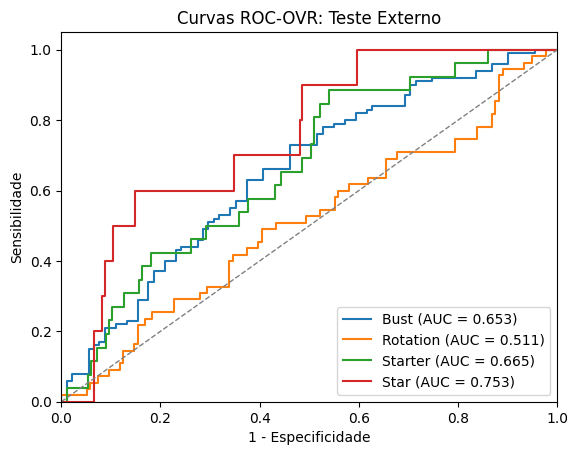

In [29]:
# Exibição das curvas ROC-OVR
plt.figure()
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    fpr, tpr, _ = roc_curve(y_bin, p_hat_teste[:, k])
    auc_k = auc(fpr, tpr)
    plt.plot(fpr, tpr, lw=1.5, label=f'{ordem_categorias[cls]} (AUC = {auc_k:.3f})')

plt.plot([0, 1], [0, 1], '--', color='gray', lw=1)
plt.xlim([0.0, 1.0]); plt.ylim([0.0, 1.05])
plt.xlabel('1 - Especificidade'); plt.ylabel('Sensibilidade')
plt.title('Curvas ROC-OVR: Teste Externo')
plt.legend(loc="lower right")
plt.show()

### **Etapa 6: Interpretabilidade do modelo final**

*Cálculo da importância por permutação para cada variável no modelo final*

In [30]:
importancias_permutacao = permutation_importance(modelo_final,
                                                 X_treino_tratada,
                                                 y_treino,
                                                 n_repeats=30,
                                                 random_state=123, 
                                                 scoring='roc_auc_ovr')
importancias_permutacao = pd.Series(importancias_permutacao.importances_mean,
                                    index=X_treino_tratada.columns).sort_values()

*Gráfico de importâncias por permutação*

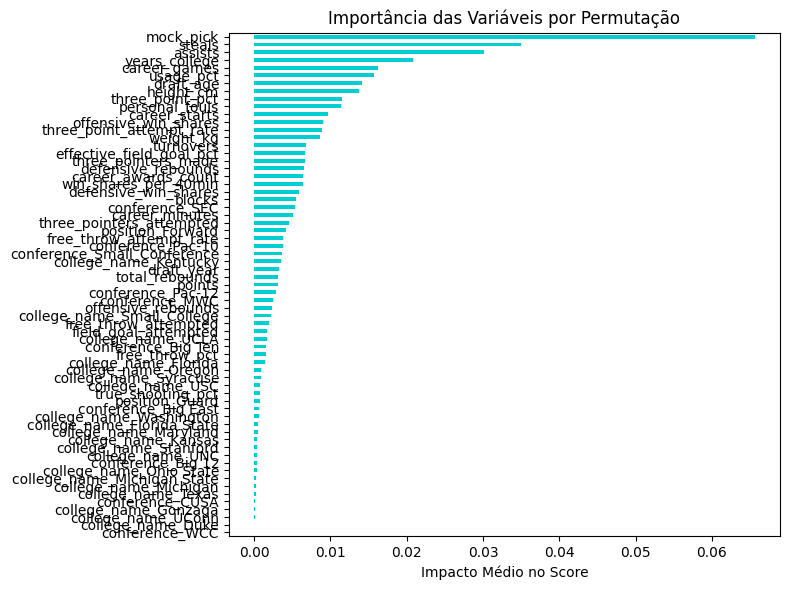

In [31]:
plt.figure(figsize=(8, 6))
importancias_permutacao.plot.barh(title="Importância das Variáveis por Permutação",
                                  color="darkturquoise")
plt.xlabel("Impacto Médio no Score")
plt.tight_layout()
plt.show()

*Cálculo dos valores SHAP das variáveis no modelo final*

In [32]:
X_amostra = shap.sample(X_treino_tratada, X_treino_tratada.shape[0], random_state=123)
explainer = shap.Explainer(modelo_final, X_amostra)
valores_shap = explainer(X_amostra)

*Gráfico de valores absolutos médios de SHAP*

Gerando SHAP Bar Plot para a classe: Bust


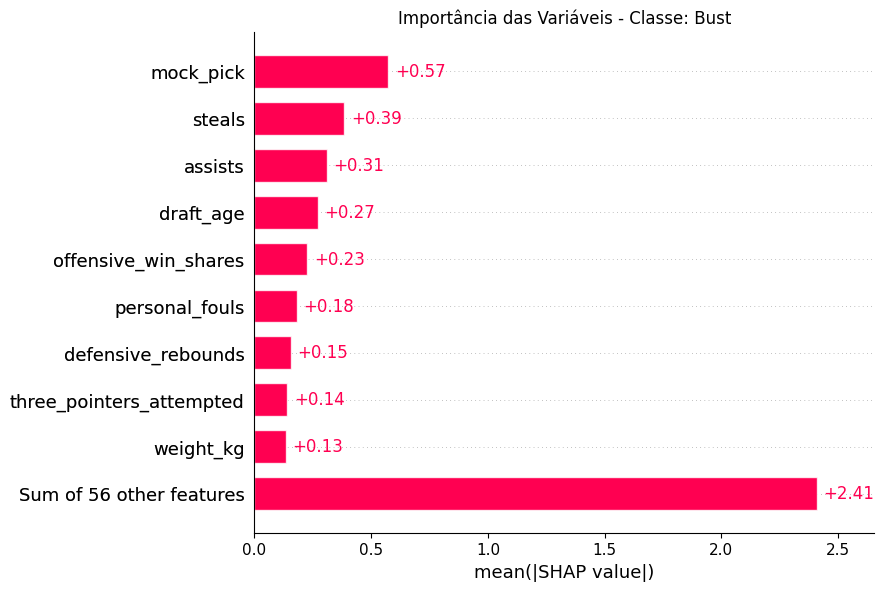

Gerando SHAP Bar Plot para a classe: Rotation


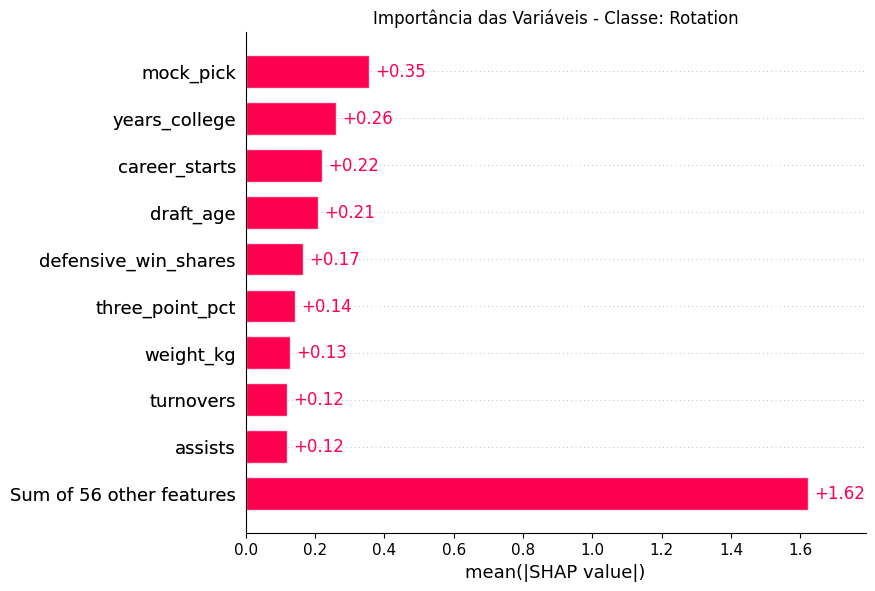

Gerando SHAP Bar Plot para a classe: Starter


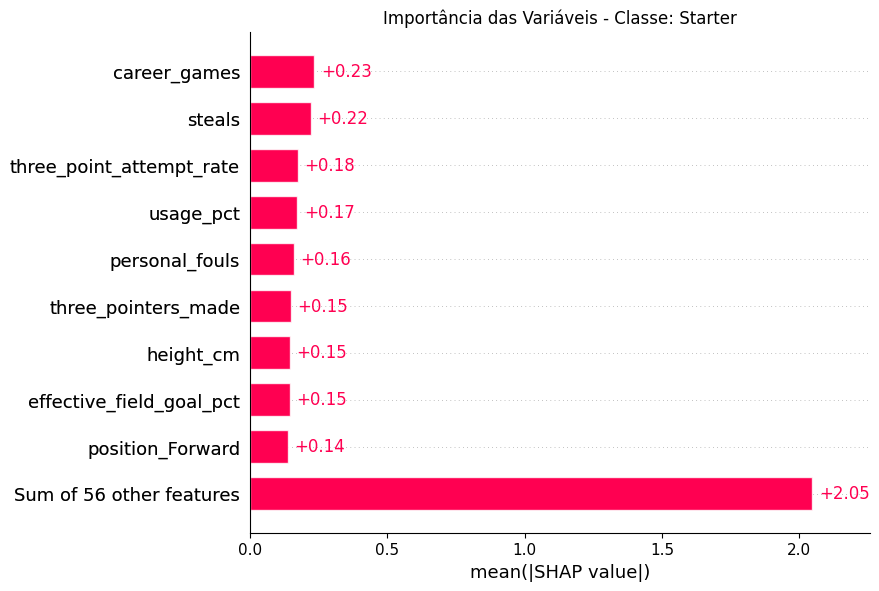

Gerando SHAP Bar Plot para a classe: Star


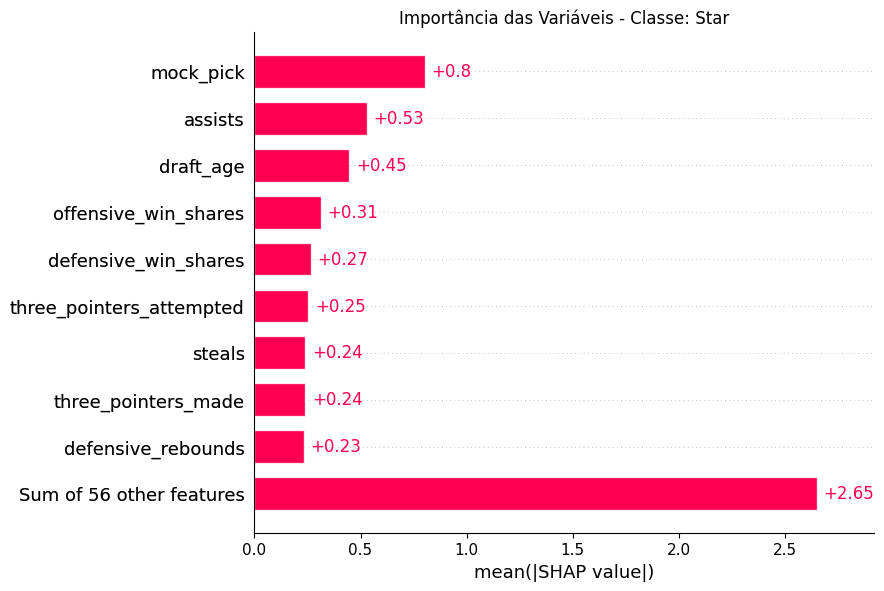

In [33]:
for i, nome in enumerate(ordem_categorias):
    print(f"Gerando SHAP Bar Plot para a classe: {nome}")
    
    # Criar a figura
    plt.figure()
    plt.title(f"Importância das Variáveis - Classe: {nome}")
    
    # Gerar o gráfico de barras para a classe i
    # valores_shap[:,:,i] acessa a explicação específica daquela categoria
    shap.plots.bar(valores_shap[:,:,i], show=False)
    
    plt.show()

    


*Gráfico de direção do impacto baseado em SHAP (beeswarm)*

Gerando SHAP beeswarm  para a classe: Bust


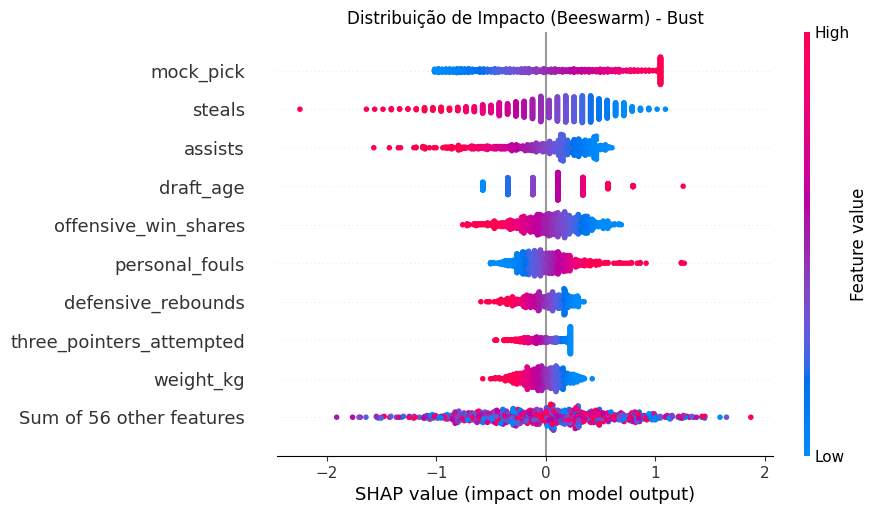

Gerando SHAP beeswarm  para a classe: Rotation


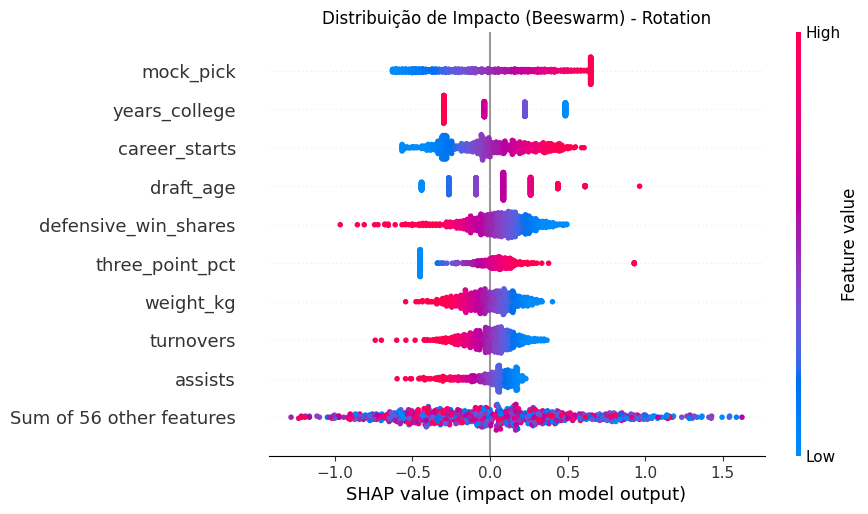

Gerando SHAP beeswarm  para a classe: Starter


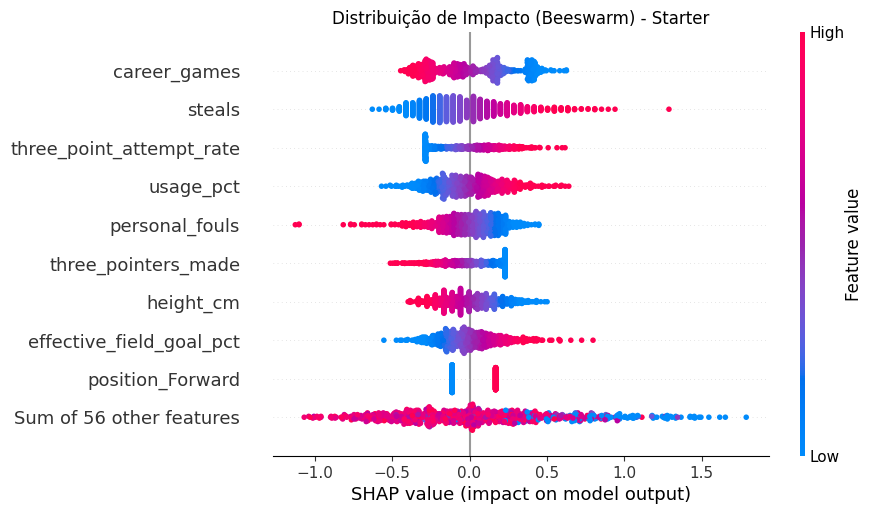

Gerando SHAP beeswarm  para a classe: Star


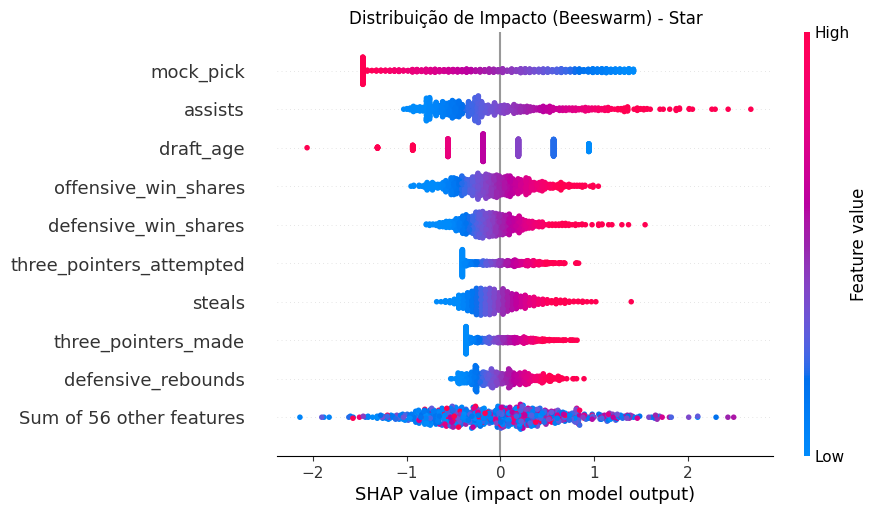

In [34]:
for i, nome in enumerate(ordem_categorias):
    print(f"Gerando SHAP beeswarm  para a classe: {nome}")
    
    # Criar a figura
    plt.figure(figsize=(10, 6))
    plt.title(f"Distribuição de Impacto (Beeswarm) - {nome}")
    # Para versões recentes do SHAP, usamos plots.beeswarm
    shap.plots.beeswarm(valores_shap[:, :, i], max_display=10, show=False)
    plt.show()

### **Etapa 7: Mudando Corte**

In [35]:
p_hat_teste = modelo_final.predict_proba(X_teste_tratada)

In [36]:
y_hat_teste_ajustado = []

for prob in p_hat_teste:
    if prob[3] >= 0.20:
        y_hat_teste_ajustado.append('Star')
        
    elif prob[2] >= 0.25:
        y_hat_teste_ajustado.append('Starter')
        
    elif prob[1] >= 0.30:
        y_hat_teste_ajustado.append('Rotation')
        
    else:
        y_hat_teste_ajustado.append('Bust')
y_hat_teste = np.array(y_hat_teste_ajustado)

*Verificação gráfica de calibração das probabilidades*

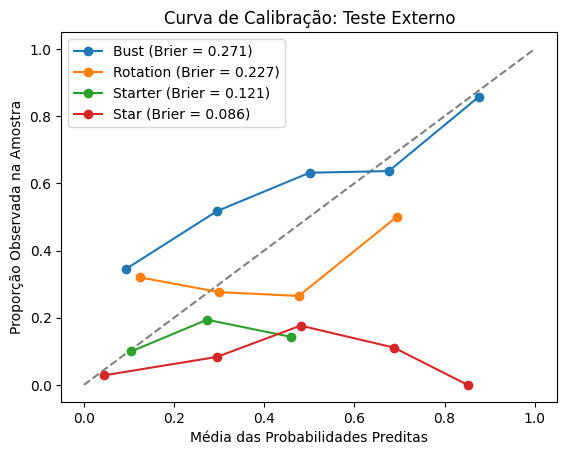

In [37]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

***(Se necessário)*** *Atualização de probabilidades preditas no teste, por meio de recalibração das probabilidades no conjunto de treino*

In [38]:
# Recalibração do modelo no treino - escolha o método: 'isotonic' (n > 1000) ou 'sigmoid'
modelo_final_calibrado = CalibratedClassifierCV(modelo_final, method='sigmoid', cv=5)
modelo_final_calibrado.fit(X_treino_tratada, y_treino)

# Armazenamento de probabilidades não calibradas e cálculo das probabilidades calibradas
p_hat_teste_nao_calibradas = p_hat_teste
p_hat_teste = modelo_final_calibrado.predict_proba(X_teste_tratada)

c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
c:\Users\caio\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


***(Em caso de subamostragem)*** *Correção de probabilidades preditas no teste, por conta de subamostragem*

In [39]:
# Cálculo de razões entre as proporções originais (antes da subamostragem) e das proporções novas (após subamostragem)
dist_y_pre_reamostragem = pd.Series(y_treino).value_counts(normalize=True).reindex(classes).to_numpy()
dist_y_pos_reamostragem = pd.Series(y_treino).value_counts(normalize=True).reindex(classes).to_numpy()
w = dist_y_pre_reamostragem / dist_y_pos_reamostragem

# Armazenamento de probabilidades calibradas e cálculo das probabilidades calibradas + corrigidas após subamostragem
p_hat_teste_calibradas = p_hat_teste
p_hat_teste = p_hat_teste * w
p_hat_teste = p_hat_teste / p_hat_teste.sum(axis=1, keepdims=True)

***(Se necessário)*** *Verificação gráfica de calibração das probabilidades - atualização pós calibração*

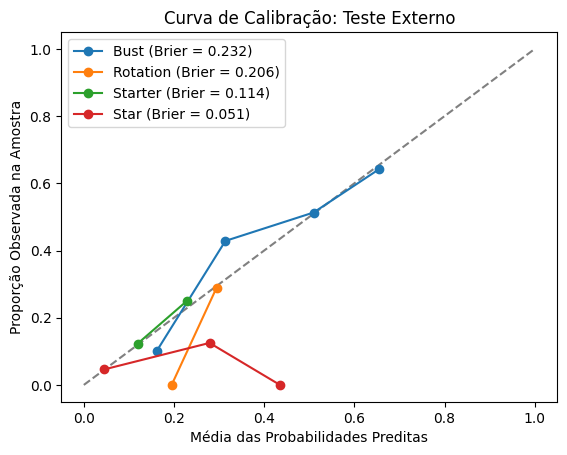

In [40]:
# Cálculos
y_one_hot = label_binarize(y_teste, classes=classes)

# Gráfico da curva de calibração para cada classe (one-versus-rest)
plt.plot([0,1],[0,1],'--', color='gray')
for k, cls in enumerate(classes):
    y_bin = (y_teste == cls).astype(int)
    prop_obs, p_hat_media = calibration_curve(y_bin, p_hat_teste[:, k])
    brier = brier_score_loss(y_bin, p_hat_teste[:, k])
    plt.plot(p_hat_media,
             prop_obs,
             'o-',
             label=f"{ordem_categorias[cls]} (Brier = {brier:.3f})")
plt.xlabel("Média das Probabilidades Preditas")
plt.ylabel("Proporção Observada na Amostra")
plt.title("Curva de Calibração: Teste Externo")
plt.legend()
plt.show()

*Tabela de classificação*

In [41]:
# Tabela de classificação com frequências absolutas
tabela = pd.crosstab(y_teste, y_hat_teste)

# O y_teste (linhas) está em formato de número (0,1,2,3). Vamos renomear para texto:
mapa_classes = {0: 'Bust', 1: 'Rotation', 2: 'Starter', 3: 'Star'}
tabela.rename(index=mapa_classes, columns=mapa_classes, inplace=True)
tabela = tabela.reindex(index=ordem_categorias, columns=ordem_categorias, fill_value=0)

display(tabela)

col_0,Bust,Rotation,Starter,Star
target_label,,,,
Bust,30,36,16,18
Rotation,11,18,9,17
Starter,4,5,6,11
Star,0,3,1,6


In [42]:
# Tabela de classificação com frequências relativas, somando 100% em cada linha
tabela_relativa_linhas = (tabela.div(tabela.sum(axis=1), axis=0)).round(3)
tabela_relativa_linhas

col_0,Bust,Rotation,Starter,Star
target_label,,,,
Bust,0.300,0.360,0.160,0.180
Rotation,0.200,0.327,0.164,0.309
Starter,0.154,0.192,0.231,0.423
Star,0.000,0.300,0.100,0.600


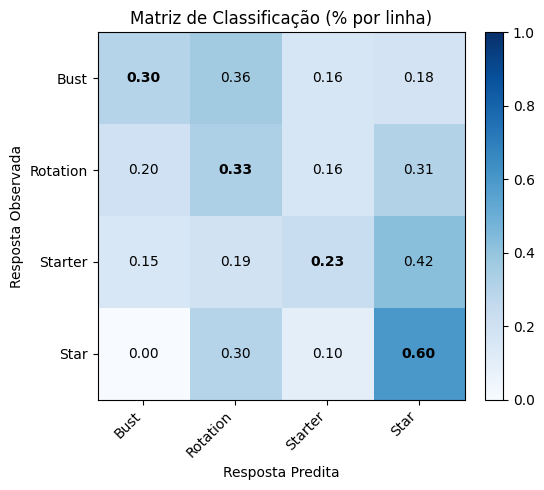

In [43]:
# Gráfico de calor com frequências relativas, somando 100% em cada linha
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_linhas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_linhas.shape[1]))
ax.set_yticks(range(tabela_relativa_linhas.shape[0]))
ax.set_xticklabels(tabela_relativa_linhas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_linhas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por linha)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

In [44]:
# Tabela de classificação com frequências relativas, somando 100% em cada coluna
tabela_relativa_colunas = (tabela.div(tabela.sum(axis=0), axis=1)).round(3)
tabela_relativa_colunas

col_0,Bust,Rotation,Starter,Star
target_label,,,,
Bust,0.667,0.581,0.500,0.346
Rotation,0.244,0.290,0.281,0.327
Starter,0.089,0.081,0.188,0.212
Star,0.000,0.048,0.031,0.115


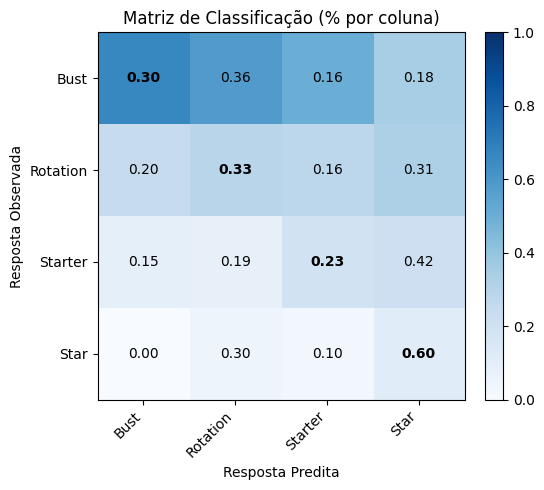

In [45]:
# Gráfico de calor com frequências relativas, somando 100% em cada coluna
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(tabela_relativa_colunas.values, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(tabela_relativa_colunas.shape[1]))
ax.set_yticks(range(tabela_relativa_colunas.shape[0]))
ax.set_xticklabels(tabela_relativa_colunas.columns, rotation=45, ha='right')
ax.set_yticklabels(tabela_relativa_colunas.index)
ax.set_xlabel("Resposta Predita"); ax.set_ylabel("Resposta Observada")
ax.set_title("Matriz de Classificação (% por coluna)")

for (i, j), v in np.ndenumerate(tabela_relativa_linhas.values):
    same_label = tabela_relativa_linhas.index[i] == tabela_relativa_linhas.columns[j]
    ax.text(j, i, f"{v:.2f}", ha="center", va="center",
            fontweight=("bold" if same_label else "normal"))

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

*Desempenho: taxas de acerto por categoria, precisões por categoria, AUC-OVR, acurácia e acurácia balanceada*

In [46]:
# Taxas de acerto por categoria (recalls)
pd.Series(
    np.diag(tabela_relativa_linhas.reindex(columns=tabela_relativa_linhas.index).to_numpy()),
    index=tabela_relativa_linhas.index
)

target_label
Bust        0.300
Rotation    0.327
Starter     0.231
Star        0.600
dtype: float64

In [47]:
# Precisões por categoria
pd.Series(
    np.diag(tabela_relativa_colunas.reindex(columns=tabela_relativa_colunas.index).to_numpy()),
    index=tabela_relativa_colunas.index
)

target_label
Bust        0.667
Rotation    0.290
Starter     0.188
Star        0.115
dtype: float64

In [48]:
y_teste_texto = y_teste.map(mapa_classes)
auc_ovr = roc_auc_score(y_teste, p_hat_teste, multi_class='ovr', average='weighted')

# 4. As acurácias agora comparam texto contra texto!
acuracia = accuracy_score(y_teste_texto, y_hat_teste)
acuracia_balanceada = balanced_accuracy_score(y_teste_texto, y_hat_teste)

print(f'AUC-OVR: {auc_ovr:.3f}')
print(f'Acurácia: {acuracia:.3f}')
print(f'Acurácia balanceada: {acuracia_balanceada:.3f}')

AUC-OVR: 0.619
Acurácia: 0.314
Acurácia balanceada: 0.365
